In [47]:
# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
# Step 2: Load the sales dataset
# Make sure sales_data_sample.csv is in the same folder as this notebook

df = pd.read_csv('sales_data_sample.csv', encoding='latin1')

# Display first five records
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [49]:
# Step 3: Display dataset information
# This shows column names, data types and non-null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [50]:
# Step 4: Display statistical summary of the dataset

df.describe()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.00000,2823.000000
mean,10258.725115,35.092809,83.658544,6.466171,3553.889072,2.717676,7.092455,2003.81509,100.715551
std,92.085478,9.741443,20.174277,4.225841,1841.865106,1.203878,3.656633,0.69967,40.187912
min,10100.000000,6.000000,26.880000,1.000000,482.130000,1.000000,1.000000,2003.00000,33.000000
25%,10180.000000,27.000000,68.860000,3.000000,2203.430000,2.000000,4.000000,2003.00000,68.000000
50%,10262.000000,35.000000,95.700000,6.000000,3184.800000,3.000000,8.000000,2004.00000,99.000000
75%,10333.500000,43.000000,100.000000,9.000000,4508.000000,4.000000,11.000000,2004.00000,124.000000
max,10425.000000,97.000000,100.000000,18.000000,14082.800000,4.000000,12.000000,2005.00000,214.000000


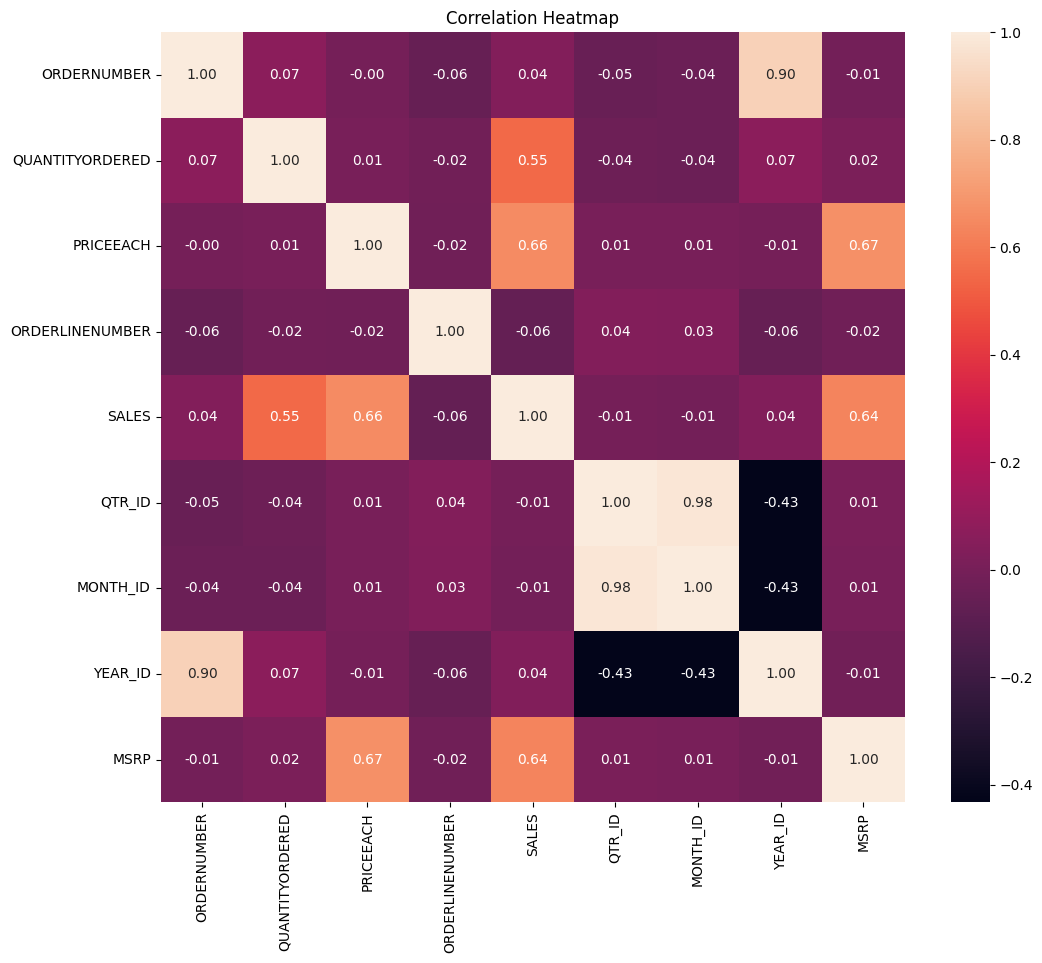

In [51]:
# Step 5: Visualize correlation between numerical columns

plt.figure(figsize=(12, 10))

sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

In [52]:
# Step 6: Select PRICEEACH and MSRP columns for clustering

df = df[['PRICEEACH', 'MSRP']]

# Display selected columns
df.head()

,PRICEEACH,MSRP
0,95.70,95
1,81.35,95
2,94.74,95
3,83.26,95
4,100.00,95


In [53]:
# Step 7: Check for missing values

df.isna().any()

PRICEEACH    False
MSRP         False
dtype: bool

In [54]:
# Step 8: Display statistical summary of selected features

df.describe().T

,count,mean,std,min,25%,50%,75%,max
PRICEEACH,2823.0,83.658544,20.174277,26.88,68.86,95.7,100.0,100.0
MSRP,2823.0,100.715551,40.187912,33.00,68.00,99.0,124.0,214.0


In [55]:
# Step 9: Display number of rows and columns

df.shape

(2823, 2)

In [56]:
# Step 9: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

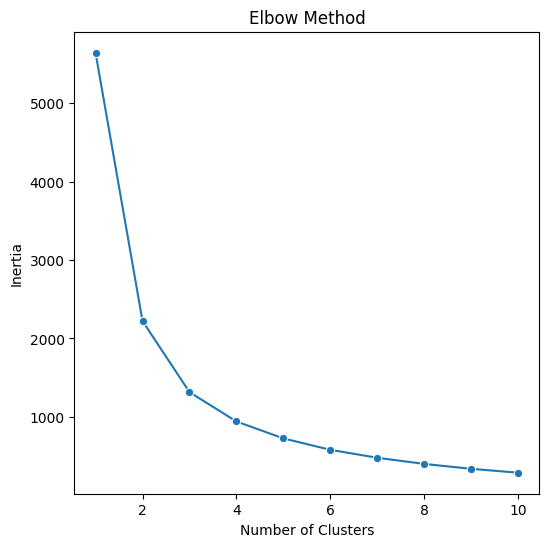

In [57]:
# Step 10: Find the optimal number of clusters using Elbow Method

from sklearn.cluster import KMeans

inertia = []

for i in range(1, 11):

    clusters = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    clusters.fit(scaled_data)
    inertia.append(clusters.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(6, 6))

sns.lineplot(x=list(range(1, 11)), y=inertia, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [58]:
# Step 11: Apply K-Means algorithm with 3 clusters

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model and predict cluster labels
y_kmeans = kmeans.fit_predict(scaled_data)

# Display cluster labels
y_kmeans

array([1, 1, 1, ..., 1, 2, 2], shape=(2823,), dtype=int32)

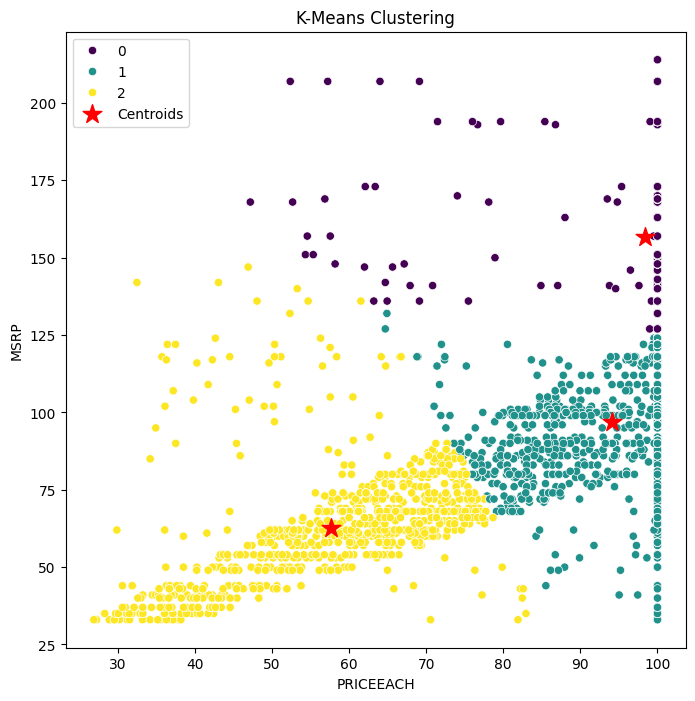

In [59]:
# Step 12: Visualize the clusters and their centroids

centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 8))

sns.scatterplot(
    x=df['PRICEEACH'],
    y=df['MSRP'],
    hue=y_kmeans,
    palette='viridis'
)

# Display cluster centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='red',
    marker='*',
    s=200,
    label='Centroids'
)

plt.xlabel("PRICEEACH")
plt.ylabel("MSRP")
plt.title("K-Means Clustering")
plt.legend()

plt.show()

In [60]:
# Display the coordinates of cluster centres

centroids

array([[ 98.32223188, 156.6       ],
       [ 94.15993559,  97.05555556],
       [ 57.66452301,  62.53984287]])